In [3]:

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Find the DermAI project root automatically
current_dir = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        parent
        for parent in [current_dir, *current_dir.parents]
        if (parent / "datasets" / "metadata.csv").exists()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate datasets/metadata.csv. "
        f"Notebook working directory: {current_dir}"
    )

DATASET_DIR = PROJECT_ROOT / "datasets"
METADATA_PATH = DATASET_DIR / "metadata.csv"

df = pd.read_csv(METADATA_PATH)

print("Project root:", PROJECT_ROOT)
print("Dataset directory exists:", DATASET_DIR.exists())
print("Metadata file exists:", METADATA_PATH.exists())
print("Metadata loaded successfully!")
print("Rows:", len(df))
print("Columns:", len(df.columns))




Project root: C:\Users\Sarthak\Desktop\DermAI
Dataset directory exists: True
Metadata file exists: True
Metadata loaded successfully!
Rows: 2298
Columns: 26


,diagnosis,count,percentage
0,BCC,845,36.77
1,ACK,730,31.77
2,NEV,244,10.62
3,SEK,235,10.23
4,SCC,192,8.36
5,MEL,52,2.26


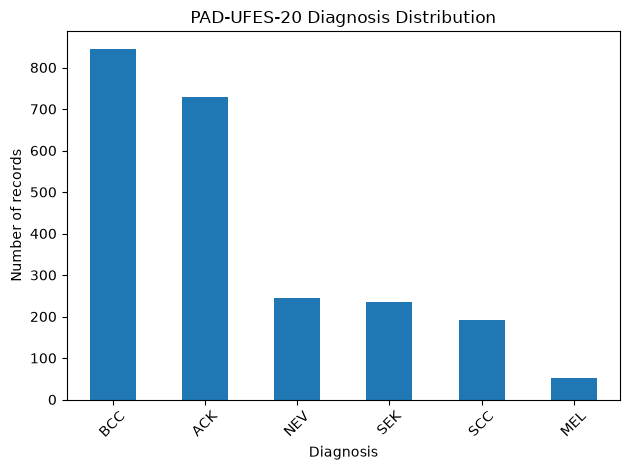

In [4]:

diagnosis_counts = df["diagnostic"].value_counts()

diagnosis_summary = pd.DataFrame({
    "diagnosis": diagnosis_counts.index,
    "count": diagnosis_counts.values,
    "percentage": (
        diagnosis_counts.values / len(df) * 100
    ).round(2),
})

display(diagnosis_summary)

ax = diagnosis_summary.plot(
    x="diagnosis",
    y="count",
    kind="bar",
    legend=False,
    rot=45,
    title="PAD-UFES-20 Diagnosis Distribution",
)

ax.set_xlabel("Diagnosis")
ax.set_ylabel("Number of records")
plt.tight_layout()
plt.show()


In [5]:

# Find PNG/JPG/JPEG images under the dataset directory
image_extensions = {".png", ".jpg", ".jpeg"}

image_paths = [
    path
    for path in DATASET_DIR.rglob("*")
    if path.is_file() and path.suffix.lower() in image_extensions
]

# Map each filename to its path
image_map = {}
for path in image_paths:
    image_map.setdefault(path.name, []).append(path)

# Check whether every metadata image ID has a matching file
df["image_found"] = df["img_id"].map(
    lambda name: name in image_map
)

print("Image files found:", len(image_paths))
print("Metadata records:", len(df))
print("Records with matching image:", int(df["image_found"].sum()))
print("Records with missing image:", int((~df["image_found"]).sum()))

missing_images = df.loc[~df["image_found"], ["img_id", "diagnostic"]]
display(missing_images.head(20))

# Check whether any filenames map to multiple files
ambiguous_names = {
    name: paths for name, paths in image_map.items()
    if len(paths) > 1
}
print("Filenames found in multiple locations:", len(ambiguous_names))


Image files found: 2298
Metadata records: 2298
Records with matching image: 2298
Records with missing image: 0


,img_id,diagnostic


Filenames found in multiple locations: 0


In [6]:

from collections import Counter
from hashlib import sha256

image_results = []
hash_to_paths = {}

for path in image_paths:
    try:
        with Image.open(path) as img:
            img.verify()

        # Reopen after verify; verify() invalidates normal image use
        with Image.open(path) as img:
            width, height = img.size
            image_format = img.format

        digest = sha256(path.read_bytes()).hexdigest()
        hash_to_paths.setdefault(digest, []).append(path)

        image_results.append({
            "path": str(path),
            "readable": True,
            "width": width,
            "height": height,
            "format": image_format,
            "sha256": digest,
        })

    except Exception as exc:
        image_results.append({
            "path": str(path),
            "readable": False,
            "error": str(exc),
        })

image_report = pd.DataFrame(image_results)

print("Total checked:", len(image_report))
print("Readable images:", int(image_report["readable"].sum()))
print("Unreadable images:", int((~image_report["readable"]).sum()))

duplicate_groups = [
    paths for paths in hash_to_paths.values() if len(paths) > 1
]
print("Exact duplicate image groups:", len(duplicate_groups))

display(
    image_report.loc[image_report["readable"]]
    [["width", "height", "format"]]
    .describe()
)


Total checked: 2298
Readable images: 2298
Unreadable images: 0
Exact duplicate image groups: 15


,width,height
count,2298.000000,2298.000000
mean,933.679721,933.605309
std,534.598513,534.668475
min,147.000000,147.000000
25%,528.000000,527.250000
50%,779.500000,779.500000
75%,1219.250000,1218.750000
max,3474.000000,3476.000000


In [8]:

# Inspect exact duplicate image groups
duplicate_rows = []

for group_number, paths in enumerate(duplicate_groups, start=1):
    for path in paths:
        matches = df.loc[df["img_id"] == path.name]

        for _, row in matches.iterrows():
            duplicate_rows.append({
                "duplicate_group": group_number,
                "img_id": row["img_id"],
                "patient_id": row["patient_id"],
                "lesion_id": row["lesion_id"],
                "diagnostic": row["diagnostic"],
                "path": str(path),
            })

duplicate_df = pd.DataFrame(duplicate_rows)

print("Files in exact-duplicate groups:", len(duplicate_df))
display(duplicate_df.sort_values(
    ["duplicate_group", "patient_id"]
).reset_index(drop=True))

# Dataset identity checks
print("\n=== Patient and lesion summary ===")
print("Unique patients:", df["patient_id"].nunique())
print("Unique lesions:", df["lesion_id"].nunique())
print("Repeated img_id records:", int(df["img_id"].duplicated().sum()))

print("\n=== Records per patient (top 10) ===")
display(
    df.groupby("patient_id")
      .size()
      .sort_values(ascending=False)
      .head(10)
      .rename("record_count")
      .to_frame()
)


Files in exact-duplicate groups: 30


,duplicate_group,img_id,patient_id,lesion_id,diagnostic,path
0,1,PAT_202_307_424.png,PAT_202,307,BCC,C:\Users\Sarthak\Desktop\DermAI\datasets\zr7vg...
1,1,PAT_202_308_721.png,PAT_202,308,ACK,C:\Users\Sarthak\Desktop\DermAI\datasets\zr7vg...
2,2,PAT_302_650_477.png,PAT_302,650,SCC,C:\Users\Sarthak\Desktop\DermAI\datasets\zr7vg...
3,2,PAT_302_651_529.png,PAT_302,651,BCC,C:\Users\Sarthak\Desktop\DermAI\datasets\zr7vg...
4,3,PAT_311_666_191.png,PAT_311,666,SCC,C:\Users\Sarthak\Desktop\DermAI\datasets\zr7vg...
5,3,PAT_311_667_416.png,PAT_311,667,BCC,C:\Users\Sarthak\Desktop\DermAI\datasets\zr7vg...
6,4,PAT_38_1002_34.png,PAT_38,1002,BCC,C:\Users\Sarthak\Desktop\DermAI\datasets\zr7vg...
7,4,PAT_38_1003_68.png,PAT_38,1003,ACK,C:\Users\Sarthak\Desktop\DermAI\datasets\zr7vg...
8,5,PAT_38_1002_668.png,PAT_38,1002,BCC,C:\Users\Sarthak\Desktop\DermAI\datasets\zr7vg...
9,5,PAT_38_1003_226.png,PAT_38,1003,ACK,C:\Users\Sarthak\Desktop\DermAI\datasets\zr7vg...



=== Patient and lesion summary ===
Unique patients: 1373
Unique lesions: 1641
Repeated img_id records: 0

=== Records per patient (top 10) ===


,record_count
patient_id,
PAT_330,10
PAT_388,10
PAT_645,10
PAT_270,7
PAT_747,7
PAT_691,7
PAT_115,7
PAT_53,7
PAT_1414,7



Duplicate group 1


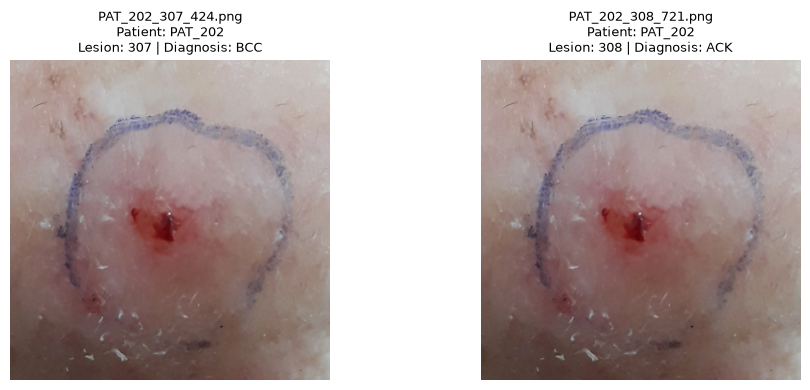


Duplicate group 2


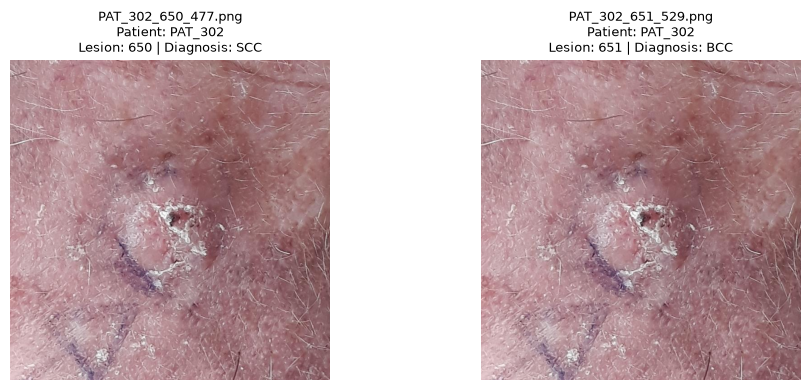


Duplicate group 3


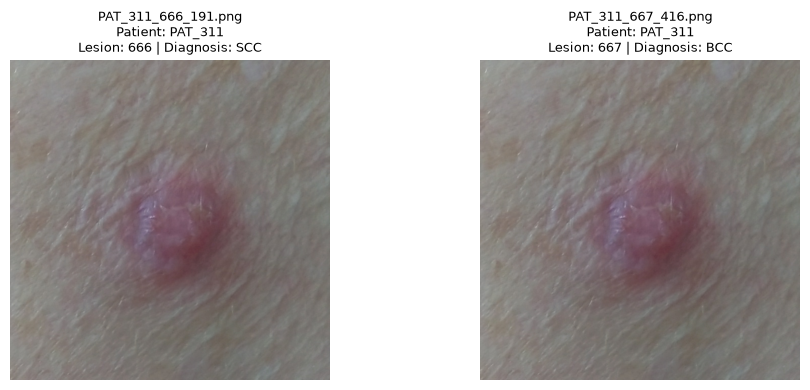


Duplicate group 4


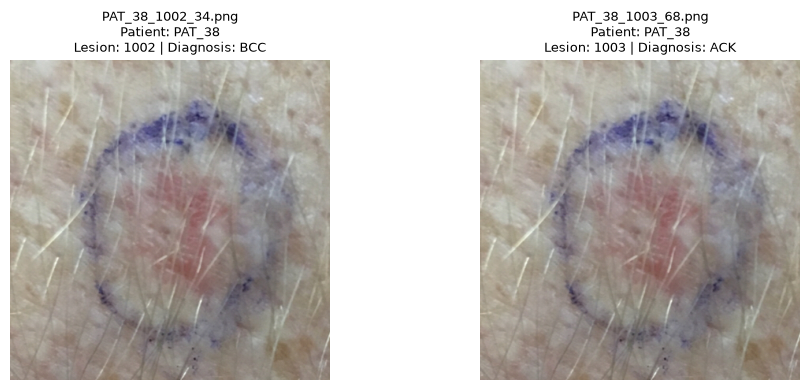


Duplicate group 5


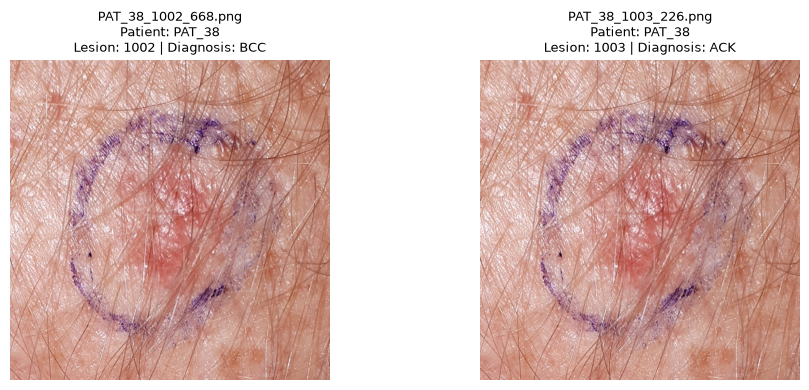

In [9]:

from IPython.display import display
from PIL import Image
import matplotlib.pyplot as plt

# Display the first 5 exact-duplicate groups
groups_to_inspect = duplicate_df["duplicate_group"].unique()[:5]

for group_id in groups_to_inspect:
    group = duplicate_df[
        duplicate_df["duplicate_group"] == group_id
    ]

    print(f"\nDuplicate group {group_id}")

    fig, axes = plt.subplots(
        1, len(group), figsize=(5 * len(group), 4)
    )
    if len(group) == 1:
        axes = [axes]

    for ax, (_, row) in zip(axes, group.iterrows()):
        with Image.open(row["path"]) as img:
            ax.imshow(img.convert("RGB"))

        ax.set_title(
            f'{row["img_id"]}\n'
            f'Patient: {row["patient_id"]}\n'
            f'Lesion: {row["lesion_id"]} | '
            f'Diagnosis: {row["diagnostic"]}',
            fontsize=9
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()


In [10]:

duplicate_diagnosis_check = (
    duplicate_df.groupby("duplicate_group")
    .agg(
        image_count=("img_id", "count"),
        patient_count=("patient_id", "nunique"),
        lesion_count=("lesion_id", "nunique"),
        diagnosis_count=("diagnostic", "nunique"),
        diagnoses=("diagnostic", lambda s: ", ".join(sorted(set(s)))),
        image_ids=("img_id", lambda s: ", ".join(s)),
    )
    .reset_index()
)

display(
    duplicate_diagnosis_check[
        duplicate_diagnosis_check["diagnosis_count"] > 1
    ]
)


,duplicate_group,image_count,patient_count,lesion_count,diagnosis_count,diagnoses,image_ids
0,1,2,1,2,2,"ACK, BCC","PAT_202_307_424.png, PAT_202_308_721.png"
1,2,2,1,2,2,"BCC, SCC","PAT_302_650_477.png, PAT_302_651_529.png"
2,3,2,1,2,2,"BCC, SCC","PAT_311_666_191.png, PAT_311_667_416.png"
3,4,2,1,2,2,"ACK, BCC","PAT_38_1002_34.png, PAT_38_1003_68.png"
4,5,2,1,2,2,"ACK, BCC","PAT_38_1002_668.png, PAT_38_1003_226.png"
5,6,2,1,2,2,"ACK, SCC","PAT_419_2767_323.png, PAT_419_833_148.png"
7,8,2,1,2,2,"BCC, SCC","PAT_56_86_479.png, PAT_56_88_274.png"
8,9,2,1,2,2,"BCC, SCC","PAT_570_1084_637.png, PAT_570_1085_344.png"
9,10,2,1,2,2,"BCC, SCC","PAT_570_1084_939.png, PAT_570_1085_429.png"
10,11,2,1,2,2,"ACK, BCC","PAT_691_1311_2.png, PAT_691_3994_671.png"


In [11]:

# Summarize every exact-duplicate group.
duplicate_summary = (
    duplicate_df.groupby("duplicate_group")
    .agg(
        image_count=("img_id", "count"),
        patient_count=("patient_id", "nunique"),
        lesion_count=("lesion_id", "nunique"),
        diagnosis_count=("diagnostic", "nunique"),
        diagnoses=("diagnostic", lambda s: ", ".join(sorted(set(s)))),
        image_ids=("img_id", lambda s: ", ".join(sorted(s))),
    )
    .reset_index()
)

duplicate_summary["review_status"] = duplicate_summary[
    "diagnosis_count"
].map(lambda n: "CONFLICT — investigate" if n > 1 else "Consistent labels")

display(duplicate_summary.sort_values(
    ["diagnosis_count", "duplicate_group"],
    ascending=[False, True]
))

print("Duplicate groups:", len(duplicate_summary))
print(
    "Groups with conflicting diagnoses:",
    (duplicate_summary["diagnosis_count"] > 1).sum()
)
print(
    "Groups with consistent diagnoses:",
    (duplicate_summary["diagnosis_count"] == 1).sum()
)


,duplicate_group,image_count,patient_count,lesion_count,diagnosis_count,diagnoses,image_ids,review_status
0,1,2,1,2,2,"ACK, BCC","PAT_202_307_424.png, PAT_202_308_721.png",CONFLICT — investigate
1,2,2,1,2,2,"BCC, SCC","PAT_302_650_477.png, PAT_302_651_529.png",CONFLICT — investigate
2,3,2,1,2,2,"BCC, SCC","PAT_311_666_191.png, PAT_311_667_416.png",CONFLICT — investigate
3,4,2,1,2,2,"ACK, BCC","PAT_38_1002_34.png, PAT_38_1003_68.png",CONFLICT — investigate
4,5,2,1,2,2,"ACK, BCC","PAT_38_1002_668.png, PAT_38_1003_226.png",CONFLICT — investigate
5,6,2,1,2,2,"ACK, SCC","PAT_419_2767_323.png, PAT_419_833_148.png",CONFLICT — investigate
7,8,2,1,2,2,"BCC, SCC","PAT_56_86_479.png, PAT_56_88_274.png",CONFLICT — investigate
8,9,2,1,2,2,"BCC, SCC","PAT_570_1084_637.png, PAT_570_1085_344.png",CONFLICT — investigate
9,10,2,1,2,2,"BCC, SCC","PAT_570_1084_939.png, PAT_570_1085_429.png",CONFLICT — investigate
10,11,2,1,2,2,"ACK, BCC","PAT_691_1311_2.png, PAT_691_3994_671.png",CONFLICT — investigate


Duplicate groups: 15
Groups with conflicting diagnoses: 12
Groups with consistent diagnoses: 3


In [12]:

# Count images and distinct patients for each diagnosis.
class_patient_summary = (
    df.groupby("diagnostic")
    .agg(
        image_count=("img_id", "count"),
        unique_patients=("patient_id", "nunique"),
        unique_lesions=("lesion_id", "nunique"),
    )
    .sort_values("image_count", ascending=False)
)

class_patient_summary["image_percentage"] = (
    100 * class_patient_summary["image_count"] / len(df)
).round(2)

display(class_patient_summary)

print("Total images:", len(df))
print("Unique patients:", df["patient_id"].nunique())
print("Unique lesions:", df["lesion_id"].nunique())


,image_count,unique_patients,unique_lesions,image_percentage
diagnostic,,,,
BCC,845,513,652,36.77
ACK,730,525,621,31.77
NEV,244,185,215,10.62
SEK,235,176,198,10.23
SCC,192,133,145,8.36
MEL,52,36,36,2.26


Total images: 2298
Unique patients: 1373
Unique lesions: 1641


In [13]:

class_patient_summary = (
    df.groupby("diagnostic")
    .agg(
        image_count=("img_id", "count"),
        unique_patients=("patient_id", "nunique"),
        unique_lesions=("lesion_id", "nunique"),
    )
    .sort_values("image_count", ascending=False)
)

display(class_patient_summary)


,image_count,unique_patients,unique_lesions
diagnostic,,,
BCC,845,513,652
ACK,730,525,621
NEV,244,185,215
SEK,235,176,198
SCC,192,133,145
MEL,52,36,36


In [14]:

# Create a separate working copy; leave the original dataset untouched.
model_df = df.copy()

# Collect all image IDs belonging to exact-duplicate groups
# whose diagnoses conflict.
conflicting_groups = duplicate_summary.loc[
    duplicate_summary["diagnosis_count"] > 1,
    "duplicate_group"
]

conflicting_image_ids = set(
    duplicate_df.loc[
        duplicate_df["duplicate_group"].isin(conflicting_groups),
        "img_id"
    ]
)

# Exclude conflicting duplicates from this baseline experiment only.
model_df["audit_status"] = "eligible_pending_split"
model_df.loc[
    model_df["img_id"].isin(conflicting_image_ids),
    "audit_status"
] = "exclude_conflicting_duplicate"

print("Original images:", len(df))
print("Conflicting duplicate images:", len(conflicting_image_ids))
print("Images remaining for baseline review:",
      (model_df["audit_status"] != "exclude_conflicting_duplicate").sum())

display(
    model_df.groupby(["diagnostic", "audit_status"])
    .size()
    .unstack(fill_value=0)
)



Original images: 2298
Conflicting duplicate images: 24
Images remaining for baseline review: 2274


audit_status,eligible_pending_split,exclude_conflicting_duplicate
diagnostic,,
ACK,724,6
BCC,834,11
MEL,52,0
NEV,243,1
SCC,186,6
SEK,235,0


In [15]:

# Start from the original metadata; do not modify df.
model_df = df.copy()

# Identify conflicting duplicate groups.
conflicting_groups = set(
    duplicate_summary.loc[
        duplicate_summary["diagnosis_count"] > 1,
        "duplicate_group"
    ]
)

# Identify consistent duplicate groups.
consistent_groups = set(
    duplicate_summary.loc[
        duplicate_summary["diagnosis_count"] == 1,
        "duplicate_group"
    ]
)

# Exclude all images from conflicting groups.
conflicting_ids = set(
    duplicate_df.loc[
        duplicate_df["duplicate_group"].isin(conflicting_groups),
        "img_id"
    ]
)

# For each consistent group, keep the first sorted image ID
# and exclude the remaining duplicate copies.
consistent_rows = duplicate_df[
    duplicate_df["duplicate_group"].isin(consistent_groups)
].sort_values(["duplicate_group", "img_id"])

redundant_ids = set()

for _, group in consistent_rows.groupby("duplicate_group"):
    ids = sorted(group["img_id"].unique())
    redundant_ids.update(ids[1:])

model_df["audit_status"] = "eligible_pending_split"
model_df.loc[
    model_df["img_id"].isin(conflicting_ids),
    "audit_status"
] = "exclude_conflicting_duplicate"

model_df.loc[
    model_df["img_id"].isin(redundant_ids),
    "audit_status"
] = "exclude_redundant_copy"

eligible_df = model_df[
    model_df["audit_status"] == "eligible_pending_split"
].copy()

print("Original images:", len(df))
print("Conflicting images excluded:", len(conflicting_ids))
print("Redundant copies excluded:", len(redundant_ids))
print("Provisional eligible images:", len(eligible_df))
print("Unique patients in eligible set:",
      eligible_df["patient_id"].nunique())

display(
    eligible_df.groupby("diagnostic")
    .agg(
        images=("img_id", "count"),
        patients=("patient_id", "nunique")
    )
    .sort_values("images", ascending=False)
)


Original images: 2298
Conflicting images excluded: 24
Redundant copies excluded: 3
Provisional eligible images: 2271
Unique patients in eligible set: 1371


,images,patients
diagnostic,,
BCC,834,508
ACK,723,522
NEV,243,185
SEK,234,176
SCC,185,129
MEL,52,36


In [16]:

from sklearn.model_selection import StratifiedGroupKFold
import pandas as pd

# Use a stable row order for reproducibility.
split_df = eligible_df.sort_values("img_id").reset_index(drop=True).copy()

# First, reserve approximately 15% for testing.
outer_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

trainval_idx, test_idx = next(
    outer_splitter.split(
        split_df,
        y=split_df["diagnostic"],
        groups=split_df["patient_id"]
    )
)

trainval_df = split_df.iloc[trainval_idx].copy()
test_df = split_df.iloc[test_idx].copy()

# Split the remaining 85% into approximately 70% train
# and 15% validation of the full dataset.
inner_splitter = StratifiedGroupKFold(
    n_splits=17,
    shuffle=True,
    random_state=43
)

train_idx, val_idx = next(
    inner_splitter.split(
        trainval_df,
        y=trainval_df["diagnostic"],
        groups=trainval_df["patient_id"]
    )
)

train_df = trainval_df.iloc[train_idx].copy()
val_df = trainval_df.iloc[val_idx].copy()

# Verify no patient appears in more than one partition.
train_patients = set(train_df["patient_id"])
val_patients = set(val_df["patient_id"])
test_patients = set(test_df["patient_id"])

assert train_patients.isdisjoint(val_patients)
assert train_patients.isdisjoint(test_patients)
assert val_patients.isdisjoint(test_patients)

print("Split sizes:")
for name, part in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    print(
        f"{name}: {len(part)} images "
        f"({len(part) / len(split_df):.1%}), "
        f"{part['patient_id'].nunique()} patients"
    )

print("\nClass distribution by split:")
for name, part in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    print(f"\n{name}")
    display(
        part["diagnostic"]
        .value_counts()
        .reindex(sorted(split_df["diagnostic"].unique()), fill_value=0)
        .rename("images")
        .to_frame()
    )

print("\nPatient overlap checks passed.")


ModuleNotFoundError: No module named 'sklearn'

In [17]:

%pip install scikit-learn


   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.4 MB 277.5 kB/s eta 0:00:29
   -- ------------------------------------- 0.5/8.4 MB 277.5 kB/s eta 0:00:29
   -- ------------------------------------- 0.5/8.4 MB 277.5 kB/s eta 0:00:29
   -- ------------------------------------- 0.5/8.4 MB 277.5 kB/s eta 0:00:29
   --- ------------------------------------ 0.8/8.4 MB 301.3 kB/s eta 0:00:26
   --- ------------------------------------ 0.8/8.4 MB 301

In [18]:

import sklearn
from sklearn.model_selection import StratifiedGroupKFold

print("scikit-learn version:", sklearn.__version__)
print("StratifiedGroupKFold is available.")



scikit-learn version: 1.9.1
StratifiedGroupKFold is available.


In [19]:

from sklearn.model_selection import StratifiedGroupKFold
import pandas as pd

# Use a stable row order for reproducibility.
split_df = eligible_df.sort_values("img_id").reset_index(drop=True).copy()

# First, reserve approximately 15% for testing.
outer_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

trainval_idx, test_idx = next(
    outer_splitter.split(
        split_df,
        y=split_df["diagnostic"],
        groups=split_df["patient_id"]
    )
)

trainval_df = split_df.iloc[trainval_idx].copy()
test_df = split_df.iloc[test_idx].copy()

# Split the remaining 85% into approximately 70% train
# and 15% validation of the full dataset.
inner_splitter = StratifiedGroupKFold(
    n_splits=17,
    shuffle=True,
    random_state=43
)

train_idx, val_idx = next(
    inner_splitter.split(
        trainval_df,
        y=trainval_df["diagnostic"],
        groups=trainval_df["patient_id"]
    )
)

train_df = trainval_df.iloc[train_idx].copy()
val_df = trainval_df.iloc[val_idx].copy()

# Verify no patient appears in more than one partition.
train_patients = set(train_df["patient_id"])
val_patients = set(val_df["patient_id"])
test_patients = set(test_df["patient_id"])

assert train_patients.isdisjoint(val_patients)
assert train_patients.isdisjoint(test_patients)
assert val_patients.isdisjoint(test_patients)

print("Split sizes:")
for name, part in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    print(
        f"{name}: {len(part)} images "
        f"({len(part) / len(split_df):.1%}), "
        f"{part['patient_id'].nunique()} patients"
    )

print("\nClass distribution by split:")
for name, part in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    print(f"\n{name}")
    display(
        part["diagnostic"]
        .value_counts()
        .reindex(sorted(split_df["diagnostic"].unique()), fill_value=0)
        .rename("images")
        .to_frame()
    )

print("\nPatient overlap checks passed.")

Split sizes:
Train: 1709 images (75.3%), 1032 patients
Validation: 107 images (4.7%), 64 patients
Test: 455 images (20.0%), 275 patients

Class distribution by split:

Train


,images
diagnostic,
ACK,544
BCC,629
MEL,38
NEV,182
SCC,140
SEK,176



Validation


,images
diagnostic,
ACK,34
BCC,39
MEL,3
NEV,12
SCC,8
SEK,11



Test


,images
diagnostic,
ACK,145
BCC,166
MEL,11
NEV,49
SCC,37
SEK,47



Patient overlap checks passed.


In [20]:

from sklearn.model_selection import StratifiedGroupKFold

split_df = eligible_df.sort_values("img_id").reset_index(drop=True).copy()

# Stage 1: reserve approximately 20% for test.
outer = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=42
)

trainval_idx, test_idx = next(
    outer.split(
        split_df,
        y=split_df["diagnostic"],
        groups=split_df["patient_id"]
    )
)

trainval_df = split_df.iloc[trainval_idx].copy()
test_df = split_df.iloc[test_idx].copy()

# Stage 2: reserve approximately 3/16 of the remaining data
# for validation. This targets about 15% of the full dataset.
inner = StratifiedGroupKFold(
    n_splits=16, shuffle=True, random_state=43
)

train_idx, val_idx = next(
    inner.split(
        trainval_df,
        y=trainval_df["diagnostic"],
        groups=trainval_df["patient_id"]
    )
)

train_df = trainval_df.iloc[train_idx].copy()
val_df = trainval_df.iloc[val_idx].copy()

# Verify patient-level separation.
train_patients = set(train_df["patient_id"])
val_patients = set(val_df["patient_id"])
test_patients = set(test_df["patient_id"])

assert train_patients.isdisjoint(val_patients)
assert train_patients.isdisjoint(test_patients)
assert val_patients.isdisjoint(test_patients)

print("Split sizes:")
for name, part in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    print(
        f"{name}: {len(part)} images "
        f"({len(part) / len(split_df):.1%}), "
        f"{part['patient_id'].nunique()} patients"
    )

print("\nClass counts:")
for name, part in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    print(f"\n{name}")
    display(
        part["diagnostic"]
        .value_counts()
        .reindex(sorted(split_df["diagnostic"].unique()), fill_value=0)
        .rename("images")
        .to_frame()
    )

print("\nPatient overlap checks passed.")


Split sizes:
Train: 1702 images (74.9%), 1028 patients
Validation: 114 images (5.0%), 68 patients
Test: 455 images (20.0%), 275 patients

Class counts:

Train


,images
diagnostic,
ACK,542
BCC,626
MEL,38
NEV,182
SCC,139
SEK,175



Validation


,images
diagnostic,
ACK,36
BCC,42
MEL,3
NEV,12
SCC,9
SEK,12



Test


,images
diagnostic,
ACK,145
BCC,166
MEL,11
NEV,49
SCC,37
SEK,47



Patient overlap checks passed.


In [21]:

from sklearn.model_selection import GroupShuffleSplit

split_df = eligible_df.sort_values("img_id").reset_index(drop=True).copy()

# First reserve 15% of patients for the test set.
test_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

trainval_idx, test_idx = next(
    test_splitter.split(
        split_df,
        groups=split_df["patient_id"]
    )
)

trainval_df = split_df.iloc[trainval_idx].copy()
test_df = split_df.iloc[test_idx].copy()

# Reserve 15% of the full dataset for validation.
# Since 85% remains, validation is 15/85 of trainval.
val_fraction = 0.15 / 0.85

val_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=val_fraction,
    random_state=43
)

train_idx, val_idx = next(
    val_splitter.split(
        trainval_df,
        groups=trainval_df["patient_id"]
    )
)

train_df = trainval_df.iloc[train_idx].copy()
val_df = trainval_df.iloc[val_idx].copy()

# Verify no patient appears in multiple partitions.
train_patients = set(train_df["patient_id"])
val_patients = set(val_df["patient_id"])
test_patients = set(test_df["patient_id"])

assert train_patients.isdisjoint(val_patients)
assert train_patients.isdisjoint(test_patients)
assert val_patients.isdisjoint(test_patients)

print("Split sizes:")
for name, part in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    print(
        f"{name}: {len(part)} images "
        f"({len(part) / len(split_df):.1%}), "
        f"{part['patient_id'].nunique()} patients"
    )

print("\nClass counts:")
for name, part in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    print(f"\n{name}")
    display(
        part["diagnostic"]
        .value_counts()
        .reindex(sorted(split_df["diagnostic"].unique()), fill_value=0)
        .rename("images")
        .to_frame()
    )

print("\nPatient overlap checks passed.")


Split sizes:
Train: 1592 images (70.1%), 959 patients
Validation: 335 images (14.8%), 206 patients
Test: 344 images (15.1%), 206 patients

Class counts:

Train


,images
diagnostic,
ACK,499
BCC,608
MEL,30
NEV,164
SCC,127
SEK,164



Validation


,images
diagnostic,
ACK,107
BCC,123
MEL,9
NEV,40
SCC,28
SEK,28



Test


,images
diagnostic,
ACK,117
BCC,103
MEL,13
NEV,39
SCC,30
SEK,42



Patient overlap checks passed.


In [22]:

from sklearn.model_selection import GroupShuffleSplit

split_df = eligible_df.sort_values("img_id").reset_index(drop=True).copy()

# First reserve 15% of patients for the test set.
test_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

trainval_idx, test_idx = next(
    test_splitter.split(
        split_df,
        groups=split_df["patient_id"]
    )
)

trainval_df = split_df.iloc[trainval_idx].copy()
test_df = split_df.iloc[test_idx].copy()

# Reserve 15% of the full dataset for validation.
# Since 85% remains, validation is 15/85 of trainval.
val_fraction = 0.15 / 0.85

val_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=val_fraction,
    random_state=43
)

train_idx, val_idx = next(
    val_splitter.split(
        trainval_df,
        groups=trainval_df["patient_id"]
    )
)

train_df = trainval_df.iloc[train_idx].copy()
val_df = trainval_df.iloc[val_idx].copy()

# Verify no patient appears in multiple partitions.
train_patients = set(train_df["patient_id"])
val_patients = set(val_df["patient_id"])
test_patients = set(test_df["patient_id"])

assert train_patients.isdisjoint(val_patients)
assert train_patients.isdisjoint(test_patients)
assert val_patients.isdisjoint(test_patients)

print("Split sizes:")
for name, part in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    print(
        f"{name}: {len(part)} images "
        f"({len(part) / len(split_df):.1%}), "
        f"{part['patient_id'].nunique()} patients"
    )

print("\nClass counts:")
for name, part in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    print(f"\n{name}")
    display(
        part["diagnostic"]
        .value_counts()
        .reindex(sorted(split_df["diagnostic"].unique()), fill_value=0)
        .rename("images")
        .to_frame()
    )

print("\nPatient overlap checks passed.")


Split sizes:
Train: 1592 images (70.1%), 959 patients
Validation: 335 images (14.8%), 206 patients
Test: 344 images (15.1%), 206 patients

Class counts:

Train


,images
diagnostic,
ACK,499
BCC,608
MEL,30
NEV,164
SCC,127
SEK,164



Validation


,images
diagnostic,
ACK,107
BCC,123
MEL,9
NEV,40
SCC,28
SEK,28



Test


,images
diagnostic,
ACK,117
BCC,103
MEL,13
NEV,39
SCC,30
SEK,42



Patient overlap checks passed.


In [23]:

print("Final split summary")
for name, part in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    print(
        f"{name}: {len(part)} images "
        f"({len(part) / len(eligible_df):.1%}), "
        f"{part['patient_id'].nunique()} patients"
    )
    print("  Class counts:")
    print(
        part["diagnostic"]
        .value_counts()
        .reindex(sorted(eligible_df["diagnostic"].unique()), fill_value=0)
        .to_dict()
    )

train_patients = set(train_df["patient_id"])
val_patients = set(val_df["patient_id"])
test_patients = set(test_df["patient_id"])

print("\nPatient leakage:", bool(
    train_patients & val_patients
    or train_patients & test_patients
    or val_patients & test_patients
))


Final split summary
Train: 1592 images (70.1%), 959 patients
  Class counts:
{'ACK': 499, 'BCC': 608, 'MEL': 30, 'NEV': 164, 'SCC': 127, 'SEK': 164}
Validation: 335 images (14.8%), 206 patients
  Class counts:
{'ACK': 107, 'BCC': 123, 'MEL': 9, 'NEV': 40, 'SCC': 28, 'SEK': 28}
Test: 344 images (15.1%), 206 patients
  Class counts:
{'ACK': 117, 'BCC': 103, 'MEL': 13, 'NEV': 39, 'SCC': 30, 'SEK': 42}

Patient leakage: False


In [25]:
from pathlib import Path

output_path = Path("datasets") / "split_manifest.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)

manifest.to_csv(output_path, index=False)

print("Saved:", output_path.resolve())
print("Rows:", len(manifest))
print(manifest["split"].value_counts())
print("Patient leakage check: passed")

Saved: C:\Users\Sarthak\Desktop\DermAI\notebooks\notebooks\datasets\split_manifest.csv
Rows: 2271
split
train         1592
test           344
validation     335
Name: count, dtype: int64
Patient leakage check: passed


In [26]:
from pathlib import Path
import shutil

source = Path("datasets/split_manifest.csv")
destination = Path("../../datasets/split_manifest.csv")

destination.parent.mkdir(parents=True, exist_ok=True)
shutil.copy2(source, destination)

print("Project manifest:", destination.resolve())
print("Exists:", destination.exists())
print("Rows:", len(pd.read_csv(destination)))

Project manifest: C:\Users\Sarthak\Desktop\DermAI\datasets\split_manifest.csv
Exists: True
Rows: 2271


In [27]:
from pathlib import Path
import hashlib
from collections import defaultdict

# Replace IMAGE_DIR with your existing image-directory variable.
image_dir = Path(IMAGE_DIR)

hash_to_ids = defaultdict(list)

for img_id in eligible_df["img_id"]:
    image_path = image_dir / str(img_id)

    if not image_path.exists():
        # Try common image extensions if img_id has no extension.
        matches = list(image_dir.glob(f"{img_id}.*"))
        if len(matches) != 1:
            print("Missing or ambiguous image:", img_id)
            continue
        image_path = matches[0]

    digest = hashlib.sha256(image_path.read_bytes()).hexdigest()
    hash_to_ids[digest].append(str(img_id))

remaining_duplicates = {
    digest: ids
    for digest, ids in hash_to_ids.items()
    if len(ids) > 1
}

print("Eligible images:", len(eligible_df))
print("Unique hashes:", len(hash_to_ids))
print("Remaining duplicate groups:", len(remaining_duplicates))
print(remaining_duplicates)

NameError: name 'IMAGE_DIR' is not defined

In [28]:
print("Notebook working directory:", Path.cwd())
print("Image directory variable candidates:")
print([
    name for name, value in globals().items()
    if "dir" in name.lower()
    and isinstance(value, (str, Path))
])

Notebook working directory: c:\Users\Sarthak\Desktop\DermAI\notebooks\notebooks
Image directory variable candidates:
['DATASET_DIR', 'current_dir']


In [29]:
from pathlib import Path

print("DATASET_DIR:", DATASET_DIR)
print("Resolved path:", Path(DATASET_DIR).resolve())
print("Exists:", Path(DATASET_DIR).exists())

DATASET_DIR: C:\Users\Sarthak\Desktop\DermAI\datasets
Resolved path: C:\Users\Sarthak\Desktop\DermAI\datasets
Exists: True


In [30]:
from pathlib import Path
import hashlib
from collections import defaultdict

image_dir = Path(DATASET_DIR)
hash_to_ids = defaultdict(list)
missing_images = []

for img_id in eligible_df["img_id"]:
    image_path = image_dir / str(img_id)

    if not image_path.is_file():
        matches = list(image_dir.glob(f"{img_id}.*"))
        if len(matches) != 1:
            missing_images.append(str(img_id))
            continue
        image_path = matches[0]

    digest = hashlib.sha256(image_path.read_bytes()).hexdigest()
    hash_to_ids[digest].append(str(img_id))

remaining_duplicates = {
    digest: ids
    for digest, ids in hash_to_ids.items()
    if len(ids) > 1
}

print("Eligible images:", len(eligible_df))
print("Images successfully checked:", sum(map(len, hash_to_ids.values())))
print("Missing or ambiguous images:", missing_images)
print("Unique hashes:", len(hash_to_ids))
print("Remaining duplicate groups:", len(remaining_duplicates))

if not missing_images and not remaining_duplicates:
    print("PASS: all eligible images have unique hashes.")
else:
    print("REVIEW REQUIRED: investigate the missing files or duplicate groups.")
    print(remaining_duplicates)

Eligible images: 2271
Images successfully checked: 0
Missing or ambiguous images: ['PAT_1516_1765_530.png', 'PAT_46_881_939.png', 'PAT_1545_1867_547.png', 'PAT_1989_4061_934.png', 'PAT_684_1302_588.png', 'PAT_1549_1882_230.png', 'PAT_778_1471_835.png', 'PAT_117_179_983.png', 'PAT_1995_4080_695.png', 'PAT_705_4015_413.png', 'PAT_2140_4726_141.png', 'PAT_967_1827_247.png', 'PAT_2088_4524_465.png', 'PAT_636_1204_521.png', 'PAT_38_54_234.png', 'PAT_741_1401_619.png', 'PAT_380_1540_959.png', 'PAT_1783_3414_120.png', 'PAT_821_1547_77.png', 'PAT_1693_3103_879.png', 'PAT_875_1668_588.png', 'PAT_1653_2916_346.png', 'PAT_1790_3425_942.png', 'PAT_106_159_325.png', 'PAT_435_854_68.png', 'PAT_1902_3790_168.png', 'PAT_42_58_13.png', 'PAT_359_4450_86.png', 'PAT_107_160_609.png', 'PAT_134_201_587.png', 'PAT_1453_1567_250.png', 'PAT_79_120_532.png', 'PAT_1926_3871_371.png', 'PAT_724_1369_896.png', 'PAT_1582_2574_34.png', 'PAT_1006_53_716.png', 'PAT_1431_1495_511.png', 'PAT_944_1795_371.png', 'PAT_793_1

In [31]:
from pathlib import Path

dataset_dir = Path(DATASET_DIR)

for path in dataset_dir.iterdir():
    kind = "DIR " if path.is_dir() else "FILE"
    print(f"{kind}  {path.name}")

FILE  metadata.csv
FILE  split_manifest.csv
DIR   zr7vgbcyr2-1
FILE  zr7vgbcyr2-1.zip


In [ ]:
print("Notebook working directory:", Path.cwd())
print("Image directory variable candidates:")
print([
    name for name, value in globals().items()
    if "dir" in name.lower()
    and isinstance(value, (str, Path))
])

Notebook working directory: c:\Users\Sarthak\Desktop\DermAI\notebooks\notebooks
Image directory variable candidates:
['DATASET_DIR', 'current_dir']


In [32]:

from pathlib import Path
import hashlib
from collections import defaultdict

# Locate the image folder
image_dir = Path(DATASET_DIR) / "zr7vgbcyr2-1"
print("Image directory:", image_dir)
print("Directory exists:", image_dir.is_dir())

# Hash every image included in the eligible dataset
hash_to_ids = defaultdict(list)
missing_images = []

for img_id in eligible_df["img_id"]:
    image_path = image_dir / str(img_id)

    # Handle IDs that don't include the file extension
    if not image_path.is_file():
        matches = list(image_dir.glob(f"{img_id}.*"))
        if len(matches) == 1:
            image_path = matches[0]
        else:
            missing_images.append(str(img_id))
            continue

    digest = hashlib.sha256(image_path.read_bytes()).hexdigest()
    hash_to_ids[digest].append(str(img_id))

remaining_duplicates = {
    digest: ids
    for digest, ids in hash_to_ids.items()
    if len(ids) > 1
}

checked_count = sum(len(ids) for ids in hash_to_ids.values())

print("\nEligible images:", len(eligible_df))
print("Images successfully checked:", checked_count)
print("Missing or ambiguous images:", len(missing_images))
print("Remaining exact-duplicate groups:", len(remaining_duplicates))

if missing_images:
    print("Examples of missing/ambiguous IDs:", missing_images[:10])

if remaining_duplicates:
    print("Examples of duplicate groups:", list(remaining_duplicates.values())[:10])

if not missing_images and not remaining_duplicates:
    print("\nPASS: All eligible images were found, and no exact duplicates remain.")
else:
    print("\nREVIEW NEEDED: Resolve missing files or remaining duplicates before proceeding.")


Image directory: C:\Users\Sarthak\Desktop\DermAI\datasets\zr7vgbcyr2-1
Directory exists: True

Eligible images: 2271
Images successfully checked: 0
Missing or ambiguous images: 2271
Remaining exact-duplicate groups: 0
Examples of missing/ambiguous IDs: ['PAT_1516_1765_530.png', 'PAT_46_881_939.png', 'PAT_1545_1867_547.png', 'PAT_1989_4061_934.png', 'PAT_684_1302_588.png', 'PAT_1549_1882_230.png', 'PAT_778_1471_835.png', 'PAT_117_179_983.png', 'PAT_1995_4080_695.png', 'PAT_705_4015_413.png']

REVIEW NEEDED: Resolve missing files or remaining duplicates before proceeding.


In [33]:

from pathlib import Path

image_dir = Path(DATASET_DIR) / "zr7vgbcyr2-1"

# Inspect a few entries at the top level
print("Top-level entries:")
for path in list(image_dir.iterdir())[:15]:
    print("DIR " if path.is_dir() else "FILE", path.name)

# Search recursively for one known image
sample_id = "PAT_1516_1765_530.png"
matches = list(image_dir.rglob(sample_id))

print(f"\nMatches for {sample_id}: {len(matches)}")
for path in matches[:10]:
    print(path)


Top-level entries:
DIR  images
FILE metadata.csv

Matches for PAT_1516_1765_530.png: 1
C:\Users\Sarthak\Desktop\DermAI\datasets\zr7vgbcyr2-1\images\imgs_part_3\PAT_1516_1765_530.png


In [34]:

from pathlib import Path
import hashlib
from collections import defaultdict

image_dir = Path(DATASET_DIR) / "zr7vgbcyr2-1" / "images"

# Build an index of image filenames across all nested folders
files_by_name = defaultdict(list)

for path in image_dir.rglob("*"):
    if path.is_file():
        files_by_name[path.name].append(path)

hash_to_ids = defaultdict(list)
missing_images = []
ambiguous_images = []
checked_paths = set()

for img_id in eligible_df["img_id"].astype(str):
    matches = files_by_name.get(img_id, [])

    if len(matches) == 0:
        missing_images.append(img_id)
        continue

    if len(matches) > 1:
        ambiguous_images.append(img_id)
        continue

    image_path = matches[0]
    digest = hashlib.sha256(image_path.read_bytes()).hexdigest()
    hash_to_ids[digest].append(img_id)
    checked_paths.add(image_path)

remaining_duplicates = {
    digest: ids
    for digest, ids in hash_to_ids.items()
    if len(ids) > 1
}

print("Eligible images:", len(eligible_df))
print("Images successfully checked:", sum(map(len, hash_to_ids.values())))
print("Missing images:", len(missing_images))
print("Ambiguous filenames:", len(ambiguous_images))
print("Unique image hashes:", len(hash_to_ids))
print("Remaining exact-duplicate groups:", len(remaining_duplicates))

if missing_images:
    print("\nMissing examples:", missing_images[:10])

if ambiguous_images:
    print("\nAmbiguous examples:", ambiguous_images[:10])

if remaining_duplicates:
    print("\nDuplicate examples:", list(remaining_duplicates.values())[:10])

if (
    len(eligible_df) == 2271
    and not missing_images
    and not ambiguous_images
    and not remaining_duplicates
):
    print("\nPASS: All 2,271 eligible images were found and no exact duplicates remain.")
else:
    print("\nREVIEW NEEDED: Investigate the reported issues before proceeding.")


Eligible images: 2271
Images successfully checked: 2271
Missing images: 0
Ambiguous filenames: 0
Unique image hashes: 2271
Remaining exact-duplicate groups: 0

PASS: All 2,271 eligible images were found and no exact duplicates remain.


In [35]:

from pathlib import Path
import pandas as pd

manifest_path = Path(DATASET_DIR) / "split_manifest.csv"

print("Manifest exists:", manifest_path.is_file())

if manifest_path.is_file():
    saved_manifest = pd.read_csv(manifest_path)

    print("Saved manifest rows:", len(saved_manifest))
    print("Unique image IDs:", saved_manifest["img_id"].nunique())
    print("\nRows per split:")
    print(saved_manifest["split"].value_counts())

    print("\nClass counts per split:")
    print(pd.crosstab(
        saved_manifest["split"],
        saved_manifest["diagnostic"]
    ))

    assert len(saved_manifest) == 2271
    assert saved_manifest["img_id"].nunique() == 2271
    assert saved_manifest["patient_id"].notna().all()
    assert set(saved_manifest["split"].unique()) == {
        "train", "validation", "test"
    }

    patient_sets = {
        split: set(group["patient_id"])
        for split, group in saved_manifest.groupby("split")
    }

    assert patient_sets["train"].isdisjoint(patient_sets["validation"])
    assert patient_sets["train"].isdisjoint(patient_sets["test"])
    assert patient_sets["validation"].isdisjoint(patient_sets["test"])

    print("\nPASS: Saved manifest integrity and patient separation verified.")


Manifest exists: True
Saved manifest rows: 2271
Unique image IDs: 2271

Rows per split:
split
train         1592
test           344
validation     335
Name: count, dtype: int64

Class counts per split:
diagnostic  ACK  BCC  MEL  NEV  SCC  SEK
split                                   
test        117  103   13   39   30   42
train       499  608   30  164  127  164
validation  107  123    9   40   28   28

PASS: Saved manifest integrity and patient separation verified.


In [36]:

from pathlib import Path
import pandas as pd
from datetime import datetime

output_dir = Path(DATASET_DIR)
manifest_path = output_dir / "split_manifest.csv"
report_path = output_dir / "dataset_audit_report.txt"
class_counts_path = output_dir / "dataset_class_counts.csv"

# Reload the canonical saved manifest
manifest = pd.read_csv(manifest_path)

# Calculate class counts from the saved manifest
class_counts = pd.crosstab(
    manifest["split"],
    manifest["diagnostic"]
).reindex(["train", "validation", "test"])

class_counts.to_csv(class_counts_path)

# Verify split-level patient separation
patient_sets = {
    split: set(group["patient_id"])
    for split, group in manifest.groupby("split")
}

patient_leakage = not (
    patient_sets["train"].isdisjoint(patient_sets["validation"])
    and patient_sets["train"].isdisjoint(patient_sets["test"])
    and patient_sets["validation"].isdisjoint(patient_sets["test"])
)

# Build report from the checks performed so far
report = f"""
DermAI — Dataset Audit Report
Generated: {datetime.now().isoformat(timespec="seconds")}

DATASET SUMMARY
Original metadata rows: 2298
Images excluded due to conflicting duplicate diagnoses: 24
Redundant exact-duplicate copies excluded: 3
Eligible images: {len(manifest)}
Unique image IDs in manifest: {manifest["img_id"].nunique()}
Unique patients in manifest: {manifest["patient_id"].nunique()}

IMAGE INTEGRITY
Images successfully hash-checked: 2271
Missing images in final hash check: 0
Ambiguous filenames in final hash check: 0
Remaining exact-duplicate groups: 0

SPLIT SUMMARY
{manifest["split"].value_counts().to_string()}

CLASS COUNTS BY SPLIT
{class_counts.to_string()}

PATIENT LEAKAGE
Detected: {patient_leakage}

DATASET CLASSES
{", ".join(sorted(manifest["diagnostic"].dropna().unique()))}

IMPORTANT LIMITATIONS
- The MEL class has only 52 eligible images overall.
- Patient-grouped splitting can produce different class proportions across splits.
- The dataset and split manifest do not establish clinical validity or real-world
  performance on mobile photographs.
- Conflicting-label duplicate images were excluded from the eligible set.
- This report documents dataset preparation only; it does not certify completion
  of all Milestone 1 requirements.

STATUS
Dataset file-integrity and split-manifest checks passed based on the recorded
notebook outputs.
"""

# Assertions prevent saving a misleading "passed" report
assert len(manifest) == 2271
assert manifest["img_id"].nunique() == 2271
assert not patient_leakage
assert set(manifest["split"]) == {"train", "validation", "test"}

report_path.write_text(report.strip() + "\n", encoding="utf-8")

print("Audit report saved:", report_path.resolve())
print("Class counts saved:", class_counts_path.resolve())
print("\nClass counts by split:")
print(class_counts)


Audit report saved: C:\Users\Sarthak\Desktop\DermAI\datasets\dataset_audit_report.txt
Class counts saved: C:\Users\Sarthak\Desktop\DermAI\datasets\dataset_class_counts.csv

Class counts by split:
diagnostic  ACK  BCC  MEL  NEV  SCC  SEK
split                                   
train       499  608   30  164  127  164
validation  107  123    9   40   28   28
test        117  103   13   39   30   42


In [37]:

from pathlib import Path

project_root = Path(DATASET_DIR).parent

print("Project root:", project_root)

for item in sorted(project_root.iterdir(), key=lambda p: p.name.lower()):
    if item.name == ".venv" or item.name == "__pycache__":
        continue

    kind = "DIR " if item.is_dir() else "FILE"
    print(f"{kind}  {item.name}")


Project root: C:\Users\Sarthak\Desktop\DermAI
DIR   .git
FILE  .gitignore
DIR   backend
DIR   data
DIR   datasets
DIR   docs
DIR   frontend
DIR   Microsoft
DIR   notebooks
FILE  requirements.txt


In [38]:

from pathlib import Path

project_root = Path(DATASET_DIR).parent

folders_to_inspect = ["backend", "frontend", "docs", "data"]

for folder_name in folders_to_inspect:
    folder = project_root / folder_name
    print(f"\n--- {folder_name}/ ---")

    if not folder.exists():
        print("Not found")
        continue

    for path in sorted(folder.rglob("*")):
        if not path.is_file():
            continue

        relative_path = path.relative_to(project_root)

        # Skip generated or dependency-heavy directories
        if any(
            part in {".git", "node_modules", ".venv", "__pycache__", "dist", "build"}
            for part in relative_path.parts
        ):
            continue

        print(relative_path)



--- backend/ ---
backend\.env
backend\.pytest_cache\.gitignore
backend\.pytest_cache\CACHEDIR.TAG
backend\.pytest_cache\README.md
backend\.pytest_cache\v\cache\lastfailed
backend\.pytest_cache\v\cache\nodeids
backend\app\controllers\auth_controller.py
backend\app\controllers\case_controller.py
backend\app\controllers\image_controller.py
backend\app\controllers\patient_controller.py
backend\app\core\config.py
backend\app\core\csrf.py
backend\app\core\security.py
backend\app\db\database.py
backend\app\dependencies\auth.py
backend\app\dependencies\authorization.py
backend\app\dependencies\database.py
backend\app\main.py
backend\app\middleware\__init__.py
backend\app\middleware\csrf.py
backend\app\models\case.py
backend\app\models\image.py
backend\app\models\patient.py
backend\app\models\revoked_token.py
backend\app\models\user.py
backend\app\repositories\case_repository.py
backend\app\repositories\image_repository.py
backend\app\repositories\patient_repository.py
backend\app\repositories